# Оценка стоимости информационных атак и защиты (Вариант 5)

**Блок А** — функции нескольких переменных, частные производные, градиент, метод Лагранжа, двойной интеграл, sympy + scipy.

## 0. Бриф
1. **Заказчик:** CISO и финансовый директор организации, защищающей ИС стоимостью **V = 10 млн ₽**.
2. **Вопрос:** сколько тратить на защиту и как разделить деньги между *предотвращением* (x₁) и *обнаружением* (x₂), чтобы суммарные потери «убытки + затраты» были минимальны?
3. **Неопределённость:** квалификация злоумышленника q ∈ [0, 1] и время пребывания в системе t ∈ [0, T(x₂)] — случайные; ожидаемый убыток = **двойной интеграл** по (q, t).
4. **Метод:** E(x₁,x₂) = ∬ P(x₁,q)·L(q,t)·f(q)·h(t) dq dt → градиент, Лагранж по бюджету B, условие оптимума λ(B*) = 1.
5. **Данные синтетические**, выводы учебные и не заменяют аудит.

In [1]:
import numpy as np, pandas as pd, sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import quad, dblquad
from scipy.optimize import minimize, minimize_scalar, brentq
from scipy.stats import beta as beta_dist
import plotly.graph_objects as go
np.random.seed(42)

# ---- параметры модели (учебные) ----
V  = 10.0   # стоимость ИС, млн руб.
a  = 1.2    # эффективность предотвращения, 1/млн руб.
T0 = 90.0   # среднее «окно» до обнаружения без мониторинга, дней (верхняя граница t)
b  = 1.2    # эффективность обнаружения: T(x2) = T0/(1+b*x2), 1/млн руб.
g  = 0.04   # скорость нанесения ущерба, 1/день (умножается на q)
ALPHA, BETA = 2.0, 2.0   # квалификация злоумышленника q ~ Beta(2,2), f(q)=6q(1-q)

### Модель
* **Вероятность успешной атаки** (зависит от затрат на предотвращение x₁ и квалификации q):
  $P(x_1,q)=e^{-a\,x_1(1-q)}$. При $x_1=0$ атака успешна всегда; против «идеального» злоумышленника ($q=1$) деньги не помогают.
* **Время пребывания** в системе $t\sim U[0,\,T(x_2)]$, $T(x_2)=\dfrac{T_0}{1+b\,x_2}$ — мониторинг сокращает окно.
* **Убыток** растёт со временем и насыщается на стоимости системы: $L(q,t)=V\,(1-e^{-g\,q\,t})$.
* **Ожидаемые убытки** — двойной интеграл с переменной границей:
$$E(x_1,x_2)=\int_0^1\!\!\int_0^{T(x_2)} P(x_1,q)\,L(q,t)\,f(q)\,\frac{1}{T(x_2)}\,dt\,dq .$$
* **Общие потери:** $C(x_1,x_2)=x_1+x_2+E(x_1,x_2)\to\min$.

## 1. Технический минимум (одинаковые 5 заданий, каждый студент — свой раздел с фото рукописи)

In [2]:
x1, x2, q, t, B_, lam = sp.symbols('x1 x2 q t B lambda', real=True)
aS, gS, VS = sp.Rational(6,5), sp.Rational(1,25), 10
R = sp.exp(-aS*x1*(1-q)) * VS*(1-sp.exp(-gS*q*t))     # подынтегральный «риск-убыток»

# Задание 1. Сложная частная производная dR/dq (произведение + цепное правило)
dRdq = sp.simplify(sp.diff(R, q))
print('1) dR/dq =', dRdq)

# Задание 2. Градиент R(x1,q,t) в точке (1; 0.5; 30)
pt = {x1:1, q:sp.Rational(1,2), t:30}
grad = [sp.diff(R, v).subs(pt) for v in (x1, q, t)]
print('2) grad R =', [round(float(gv),4) for gv in grad])

# Задание 3. Лагранж (упрощённая сепарабельная модель):
#   E = 4 e^{-1.2 x1} + 3 e^{-x2} -> min,  x1 + x2 = 2
E3 = 4*sp.exp(-sp.Rational(6,5)*x1) + 3*sp.exp(-x2)
Lg = E3 + lam*(x1 + x2 - 2)
sol = sp.nsolve([sp.diff(Lg,x1), sp.diff(Lg,x2), sp.diff(Lg,lam)], [x1,x2,lam], [1,1,1])
print('3) x1*=%.4f  x2*=%.4f  lambda=%.4f' % tuple(sol))

# Задание 4. Двойной интеграл (линейная модель убытка L = V q t / T при x1 = 0):
#   E = ∬_{[0,1]x[0,T]} 6q(1-q) * V q t / T * (1/T) dt dq
TT = sp.Integer(90)
I4 = sp.integrate(6*q*(1-q) * VS*q*t/TT / TT, (t,0,TT), (q,0,1))
print('4) ∬ =', I4)

# Задание 5. Численная проверка заданий 3 и 4 через scipy
r3 = minimize(lambda x: 4*np.exp(-1.2*x[0]) + 3*np.exp(-x[1]), [1,1],
              constraints={'type':'eq','fun':lambda x: x[0]+x[1]-2})
r4, e4 = dblquad(lambda t_, q_: 6*q_*(1-q_)*10*q_*t_/90/90, 0, 1, 0, 90)
print('5) scipy: x* =', r3.x.round(4), '| ∬ =', round(r4,6), '± %.1e' % e4)

1) dR/dq = 2*(t - 30*x1*(1 - exp(q*t/25)))*exp(-q*t/25 + 6*x1*(q - 1)/5)/5
2) grad R = [-1.4857, 6.5857, 0.0602]
3) x1*=1.1227  x2*=0.8773  lambda=1.2477
4) ∬ = 5/2
5) scipy: x* = [1.1227 0.8773] | ∬ = 2.5 ± 4.9e-14


| № | Задание | Ручной расчёт | sympy/scipy | Что значит для ИБ |
|---|---|---|---|---|
| 1 | ∂R/∂q | $V e^{-a x_1(1-q)}\,[a x_1(1-e^{-gqt}) + g t\,e^{-gqt}]$ | см. вывод | Рост квалификации злоумышленника увеличивает убыток двумя путями: легче пробить защиту и быстрее нанести ущерб |
| 2 | ∇R в (1; 0,5; 30) | ≈ (−1,49; 6,59; 0,060) | см. вывод | Самая чувствительная координата — q: «кто атакует» важнее, чем «сколько он внутри» |
| 3 | Лагранж | x₁≈1,123, x₂≈0,877, λ≈1,248 | nsolve / minimize | λ>1: ещё 1 млн бюджета снизит убытки на ~1,25 млн — бюджет надо увеличивать |
| 4 | ∬ | 2,5 млн ₽ | 2,5 | Без защиты и при линейном росте ущерба ожидаемый убыток — 25 % стоимости ИС |
| 5 | scipy | — | совпадает | Ручной счёт подтверждён численно |

## 2. Генерация данных (синтетика) и проверка

{'count': 20000.0, 'mean': 0.501, 'std': 0.222, 'min': 0.006, '25%': 0.33, '50%': 0.499, '75%': 0.674, 'max': 0.997} 
Данные подходят: True


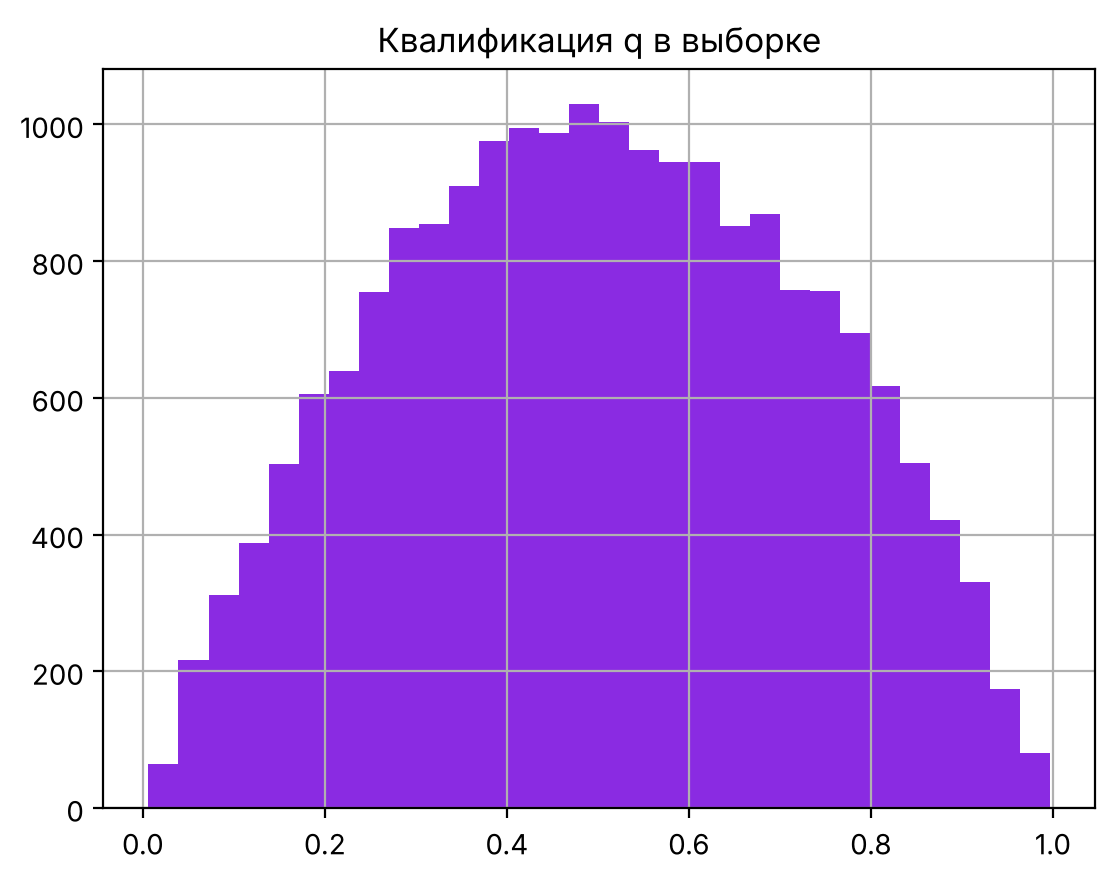

In [3]:
N = 20000
np.random.seed(7)
# q ~ Beta(2,2) в целом; профиль — подпись по уровню квалификации
q_s = np.random.beta(ALPHA, BETA, N)
u_s = np.random.uniform(0, 1, N)   # доля окна обнаружения, t = u * T(x2)
df = pd.DataFrame({'attack_id': np.arange(1, N+1), 'q': q_s.round(5), 'u': u_s.round(5)})
df['profile'] = pd.cut(df.q, [0,.25,.5,.75,1], labels=['script_kiddie','criminal_group','insider','apt'])
df.to_csv('attacks_synthetic.csv', index=False)

# проверка: q не скучено около 0.5, есть «слабые» и «сильные»
chk = df.q.describe()
ok = (df.q < .2).mean() > .05 and (df.q > .8).mean() > .05 and abs(df.q.mean()-.5) < .03
print(chk.round(3).to_dict(), '\nДанные подходят:', ok)
df.q.hist(bins=30, color='#8A2BE2'); plt.title('Квалификация q в выборке'); plt.show()

## 3. Основной расчёт
### 3.1. Внутренний интеграл по t — аналитически (sympy)

In [4]:
tt, qq, TT_, gg = sp.symbols('t q T g', positive=True)
inner = sp.simplify(sp.integrate(1 - sp.exp(-gg*qq*tt), (tt, 0, TT_)) / TT_)
print('(1/T)∫(1-e^{-gqt})dt =', inner)   # = 1 - (1 - e^{-gqT})/(gqT)

def phi(z):
    z = np.asarray(z, float)
    out = np.empty_like(z)
    small = z < 1e-6
    out[small] = z[small]/2
    out[~small] = 1 + np.expm1(-z[~small]) / z[~small]
    return out

def f_q(qv, A=ALPHA, Bb=BETA): return beta_dist.pdf(qv, A, Bb)
def T_of(x2_, T0_=T0, b_=b): return T0_/(1 + b_*x2_)

def E(x1_, x2_, a_=a, b_=b, g_=g, T0_=T0, A=ALPHA, Bb=BETA, V_=V):
    T = T_of(x2_, T0_, b_)
    integrand = lambda qv: f_q(qv, A, Bb)*np.exp(-a_*x1_*(1-qv))*V_*phi(np.array([g_*qv*T]))[0]
    return quad(integrand, 0, 1, epsabs=1e-10)[0]

def E_dbl(x1_, x2_):
    T = T_of(x2_)
    return dblquad(lambda t_, q_: f_q(q_)*np.exp(-a*x1_*(1-q_))*V*(1-np.exp(-g*q_*t_))/T, 0, 1, 0, T, epsabs=1e-10)

(1/T)∫(1-e^{-gqt})dt = 1 - 1/(T*g*q) + exp(-T*g*q)/(T*g*q)


### 3.2. Проверка: три способа посчитать один интеграл + оценка погрешности

In [5]:
for p in [(0,0), (1,0.5), (0.985,0.642)]:
    e1 = E(*p); e2, err = E_dbl(*p)
    T = T_of(p[1])
    mc_vals = f_q(df.q)/f_q(df.q)*np.exp(-a*p[0]*(1-df.q))*V*(1-np.exp(-g*df.q*df.u*T))  # выборка уже из f(q)
    mc, se = mc_vals.mean(), mc_vals.std(ddof=1)/np.sqrt(len(df))
    print(f'x={p}:  quad∘sympy={e1:.6f}  dblquad={e2:.6f} (abserr {err:.1e})  Monte-Carlo по CSV={mc:.4f} ± {1.96*se:.4f}')

x=(0, 0):  quad∘sympy=5.045427  dblquad=5.045427 (abserr 9.4e-14)  Monte-Carlo по CSV=5.0619 ± 0.0369
x=(1, 0.5):  quad∘sympy=2.354197  dblquad=2.354197 (abserr 4.8e-14)  Monte-Carlo по CSV=2.3599 ± 0.0248
x=(0.985, 0.642):  quad∘sympy=2.218941  dblquad=2.218941 (abserr 4.6e-14)  Monte-Carlo по CSV=2.2243 ± 0.0238


### 3.3. Градиент и производная по переменной границе (правило Лейбница)
$\dfrac{\partial E}{\partial x_1}=-\int_0^1 a(1-q)\,P\,V\,\varphi(gqT)\,f(q)\,dq,\qquad
\dfrac{\partial E}{\partial x_2}=\int_0^1 P\,V\,\varphi'(gqT)\,gq\,T'(x_2)\,f(q)\,dq,\quad T'=-\dfrac{bT_0}{(1+bx_2)^2}$

In [6]:
zz = sp.symbols('z', positive=True)
phi_s = 1 - (1 - sp.exp(-zz))/zz
dphi = sp.lambdify(zz, sp.diff(phi_s, zz), 'numpy')
print("φ'(z) =", sp.simplify(sp.diff(phi_s, zz)))

def grad_E(x1_, x2_):
    T = T_of(x2_); dT = -b*T0/(1+b*x2_)**2
    d1 = quad(lambda qv: -a*(1-qv)*f_q(qv)*np.exp(-a*x1_*(1-qv))*V*phi(np.array([g*qv*T]))[0], 0, 1)[0]
    d2 = quad(lambda qv: f_q(qv)*np.exp(-a*x1_*(1-qv))*V*dphi(g*qv*T + 1e-12)*g*qv*dT, 0, 1)[0]
    return np.array([d1, d2])

h = 1e-5
num = [(E(1+h,.5)-E(1-h,.5))/(2*h), (E(1,.5+h)-E(1,.5-h))/(2*h)]
print('∇E(1;0.5) аналит. =', grad_E(1,.5).round(6), '| конечные разности =', np.round(num,6))

φ'(z) = (-z + exp(z) - 1)*exp(-z)/z**2
∇E(1;0.5) аналит. = [-1.063706 -1.127042] | конечные разности = [-1.063706 -1.127042]


### 3.4. Оптимум: прямой поиск и метод Лагранжа
Для каждого бюджета B: $\min E(x_1,x_2)$ при $x_1+x_2=B$. Множитель $\lambda(B)=-\partial E/\partial x_i$ — **сколько миллионов убытков «покупает» последний миллион защиты**. Оптимальный бюджет — где $\lambda(B^*)=1$.

In [7]:
C = lambda x: x[0] + x[1] + E(x[0], x[1])
res = minimize(C, [1, 1], bounds=[(0, 10), (0, 10)], jac=lambda x: np.ones(2) + grad_E(*x))
x_opt = res.x; B_opt_direct = x_opt.sum()
print('Прямой поиск: x1*=%.3f  x2*=%.3f  B*=%.3f  E*=%.3f  C*=%.3f' % (*x_opt, B_opt_direct, E(*x_opt), res.fun))

def split(B):
    if B <= 0: return 0.0, 0.0, E(0, 0)
    r = minimize_scalar(lambda s: E(s, B-s), bounds=(0, B), method='bounded', options={'xatol':1e-7})
    return r.x, B - r.x, r.fun

def lam_of(B):
    s1, s2, _ = split(B)
    gr = grad_E(s1, s2)
    return -gr[0] if s1 > 1e-4 else -gr[1]

B_star = brentq(lambda B: lam_of(B) - 1, 0.3, 5)
s1, s2, Es = split(B_star)
print('Лагранж:      B*=%.3f  (x1=%.3f, x2=%.3f)  λ(B*)=%.4f  ∂E/∂x1=%.4f ∂E/∂x2=%.4f' % (B_star, s1, s2, lam_of(B_star), *grad_E(s1, s2)))

Bs = np.linspace(0, 5, 51)
tab = pd.DataFrame([(B, *split(B)) for B in Bs], columns=['B','x1','x2','E'])
tab['C'] = tab.B + tab.E
tab['lambda'] = [lam_of(B) if B > 0 else np.nan for B in tab.B]
tab.round(3).iloc[::5]

Прямой поиск: x1*=0.985  x2*=0.642  B*=1.626  E*=2.220  C*=3.846
Лагранж:      B*=1.626  (x1=0.985, x2=0.642)  λ(B*)=1.0000  ∂E/∂x1=-1.0000 ∂E/∂x2=-1.0000


,B,x1,x2,E,C,lambda
0,0.0,0.000,0.000,5.045,5.045,NaN
5,0.5,0.053,0.447,3.805,4.305,1.931
10,1.0,0.472,0.528,2.972,3.972,1.431
15,1.5,0.882,0.618,2.351,3.851,1.073
20,2.0,1.285,0.715,1.882,3.882,0.815
25,2.5,1.680,0.820,1.524,4.024,0.626
30,3.0,2.069,0.931,1.247,4.247,0.487
35,3.5,2.452,1.048,1.031,4.531,0.383
40,4.0,2.830,1.170,0.860,4.860,0.304
45,4.5,3.202,1.298,0.724,5.224,0.244


### 3.5. Сравнение стратегий

In [8]:
strategies = {
  'Без защиты':            (0, 0),
  'Только предотвращение': (minimize_scalar(lambda x: x + E(x, 0), bounds=(0,6), method='bounded').x, 0),
  'Только обнаружение':    (0, minimize_scalar(lambda x: x + E(0, x), bounds=(0,6), method='bounded').x),
  'Оптимум (Лагранж)':     tuple(x_opt),
}
st = pd.DataFrame([(k, v[0], v[1], v[0]+v[1], E(*v), v[0]+v[1]+E(*v)) for k, v in strategies.items()],
                  columns=['Стратегия','x1','x2','Затраты','Ожид. убытки','Общие потери'])
st.round(3)

,Стратегия,x1,x2,Затраты,Ожид. убытки,Общие потери
0,Без защиты,0.000,0.000,0.000,5.045,5.045
1,Только предотвращение,1.625,0.000,1.625,2.332,3.958
2,Только обнаружение,0.000,1.265,1.265,2.753,4.019
3,Оптимум (Лагранж),0.985,0.642,1.626,2.220,3.846


## 4. Визуализация
### 4.1. 3D: поверхность общих потерь C(x₁, x₂)

In [9]:
gx = np.linspace(0, 3, 41); gy = np.linspace(0, 3, 41)
Z = np.array([[xx + yy + E(xx, yy) for xx in gx] for yy in gy])
fig3d = go.Figure([go.Surface(x=gx, y=gy, z=Z, colorscale='Purples_r', colorbar=dict(title='C, млн')),
                   go.Scatter3d(x=[x_opt[0]], y=[x_opt[1]], z=[res.fun], mode='markers+text',
                                marker=dict(size=6, color='#FF2DA0'), text=['оптимум'])])
fig3d.update_layout(title='Общие потери C(x₁,x₂) = x₁ + x₂ + E(x₁,x₂)',
                    scene=dict(xaxis_title='x₁ предотвращение, млн', yaxis_title='x₂ обнаружение, млн', zaxis_title='C, млн'))
fig3d.show()

### 4.2. Интерактив: слайдер «квалификация злоумышленника» — кривая потерь и оптимальное распределение

In [10]:
ms = np.round(np.linspace(0.2, 0.8, 13), 2)
Bgrid = np.linspace(0, 5, 41)
frames, first = [], None
for m in ms:
    A_, B2 = 6*m, 6*(1-m)    # Beta с тем же разбросом, среднее m
    Eb = lambda x1_, x2_: E(x1_, x2_, A=A_, Bb=B2)
    rows = []
    for Bv in Bgrid:
        if Bv == 0: rows.append((0, 0, Eb(0, 0))); continue
        r = minimize_scalar(lambda s: Eb(s, Bv - s), bounds=(0, Bv), method='bounded')
        rows.append((r.x, Bv - r.x, r.fun))
    rows = np.array(rows); Ctot = Bgrid + rows[:, 2]; k = Ctot.argmin()
    data = [go.Scatter(x=Bgrid, y=Ctot, name='Общие потери C(B)', line=dict(color='#8A2BE2', width=3)),
            go.Scatter(x=Bgrid, y=rows[:, 2], name='Ожидаемые убытки E', line=dict(color='#FF2DA0', dash='dash')),
            go.Scatter(x=Bgrid, y=rows[:, 0], name='x₁ (предотвращение)', yaxis='y2', line=dict(color='#2B2B2B')),
            go.Scatter(x=Bgrid, y=rows[:, 1], name='x₂ (обнаружение)', yaxis='y2', line=dict(color='#00A6A6')),
            go.Scatter(x=[Bgrid[k]], y=[Ctot[k]], mode='markers', marker=dict(size=12, color='#FF2DA0'),
                       name=f'B* ≈ {Bgrid[k]:.2f} млн')]
    frames.append(go.Frame(data=data, name=str(m)))
    if first is None: first = data
figI = go.Figure(data=frames[len(ms)//2].data, frames=frames)
figI.update_layout(
    title='Оптимальный бюджет и его распределение в зависимости от средней квалификации q̄',
    xaxis_title='Бюджет B, млн', yaxis=dict(title='млн руб.'),
    yaxis2=dict(title='доля бюджета, млн', overlaying='y', side='right'),
    sliders=[dict(active=len(ms)//2, currentvalue=dict(prefix='q̄ = '),
                  steps=[dict(method='animate', label=str(m), args=[[str(m)], dict(mode='immediate', frame=dict(duration=0, redraw=True))]) for m in ms])])
figI.write_html('interactive_budget.html', include_plotlyjs='cdn')
figI.show()

## 5. Границы применимости и устойчивость к шуму

In [11]:
# (а) где оптимум «уходит в угол»: перестаёт быть выгодной одна из мер
rows = []
for m in np.linspace(0.1, 0.95, 35):
    A_, B2 = 6*m, 6*(1-m)
    Cm = lambda x: x[0] + x[1] + E(x[0], x[1], A=A_, Bb=B2)
    r = minimize(Cm, [0.8, 0.5], bounds=[(0, 10), (0, 10)], method='L-BFGS-B')
    rows.append((m, *r.x, r.fun, Cm([0,0])))
bd = pd.DataFrame(rows, columns=['m','x1','x2','C','C0'])
m_crit = bd[bd.x1 < 1e-3].m.min()
print('При средней квалификации q̄ ≳ %.2f вложения в предотвращение становятся нулевыми' % m_crit)

# (б) чувствительность к скорости ущерба g: когда обнаружение перестаёт окупаться
rows = []
for gv in np.linspace(0.005, 0.12, 47):
    r = minimize(lambda x: x[0]+x[1]+E(x[0], x[1], g_=gv), [0.8, 0.5], bounds=[(0,10),(0,10)], method='L-BFGS-B')
    rows.append((gv, *r.x))
bg = pd.DataFrame(rows, columns=['g','x1','x2'])
inner_ = bg[(bg.x1 > 1e-3) & (bg.x2 > 1e-3)].g
g_lo, g_hi = inner_.min(), inner_.max()
print('Обе меры ненулевые только при g ∈ [%.3f; %.3f] 1/день' % (g_lo, g_hi))
print('g ниже — только обнаружение; g выше (быстрый ущерб, шифровальщик) — только предотвращение')

При средней квалификации q̄ ≳ 0.72 вложения в предотвращение становятся нулевыми


Обе меры ненулевые только при g ∈ [0.022; 0.060] 1/день
g ниже — только обнаружение; g выше (быстрый ущерб, шифровальщик) — только предотвращение


In [12]:
# (в) шум: ключевые параметры a, b, g ±10 % (норм.), затраты (цена 1 млн защиты) ±20 %
K = 300; out = []
for _ in range(K):
    an, bn, gn = a*np.random.normal(1, .10), b*np.random.normal(1, .10), g*np.random.normal(1, .10)
    cost = np.random.normal(1, .20)
    r = minimize(lambda x: cost*(x[0]+x[1]) + E(x[0], x[1], a_=an, b_=bn, g_=gn), [1, .6],
                 bounds=[(0,10),(0,10)], method='L-BFGS-B')
    # «сожаление»: сколько теряем, если в шумном мире применяем номинальный x_opt
    regret = cost*x_opt.sum() + E(*x_opt, a_=an, b_=bn, g_=gn) - r.fun
    out.append((*r.x, r.x.sum(), regret))
nz = pd.DataFrame(out, columns=['x1','x2','B','regret'])
print(nz.describe(percentiles=[.05,.5,.95]).round(3))

            x1       x2        B   regret
count  300.000  300.000  300.000  300.000
mean     0.959    0.653    1.612    0.059
std      0.471    0.252    0.411    0.068
min      0.000    0.000    0.775    0.000
5%       0.163    0.204    1.040    0.002
50%      0.965    0.662    1.557    0.035
95%      1.693    1.041    2.418    0.186
max      2.682    1.283    3.231    0.425


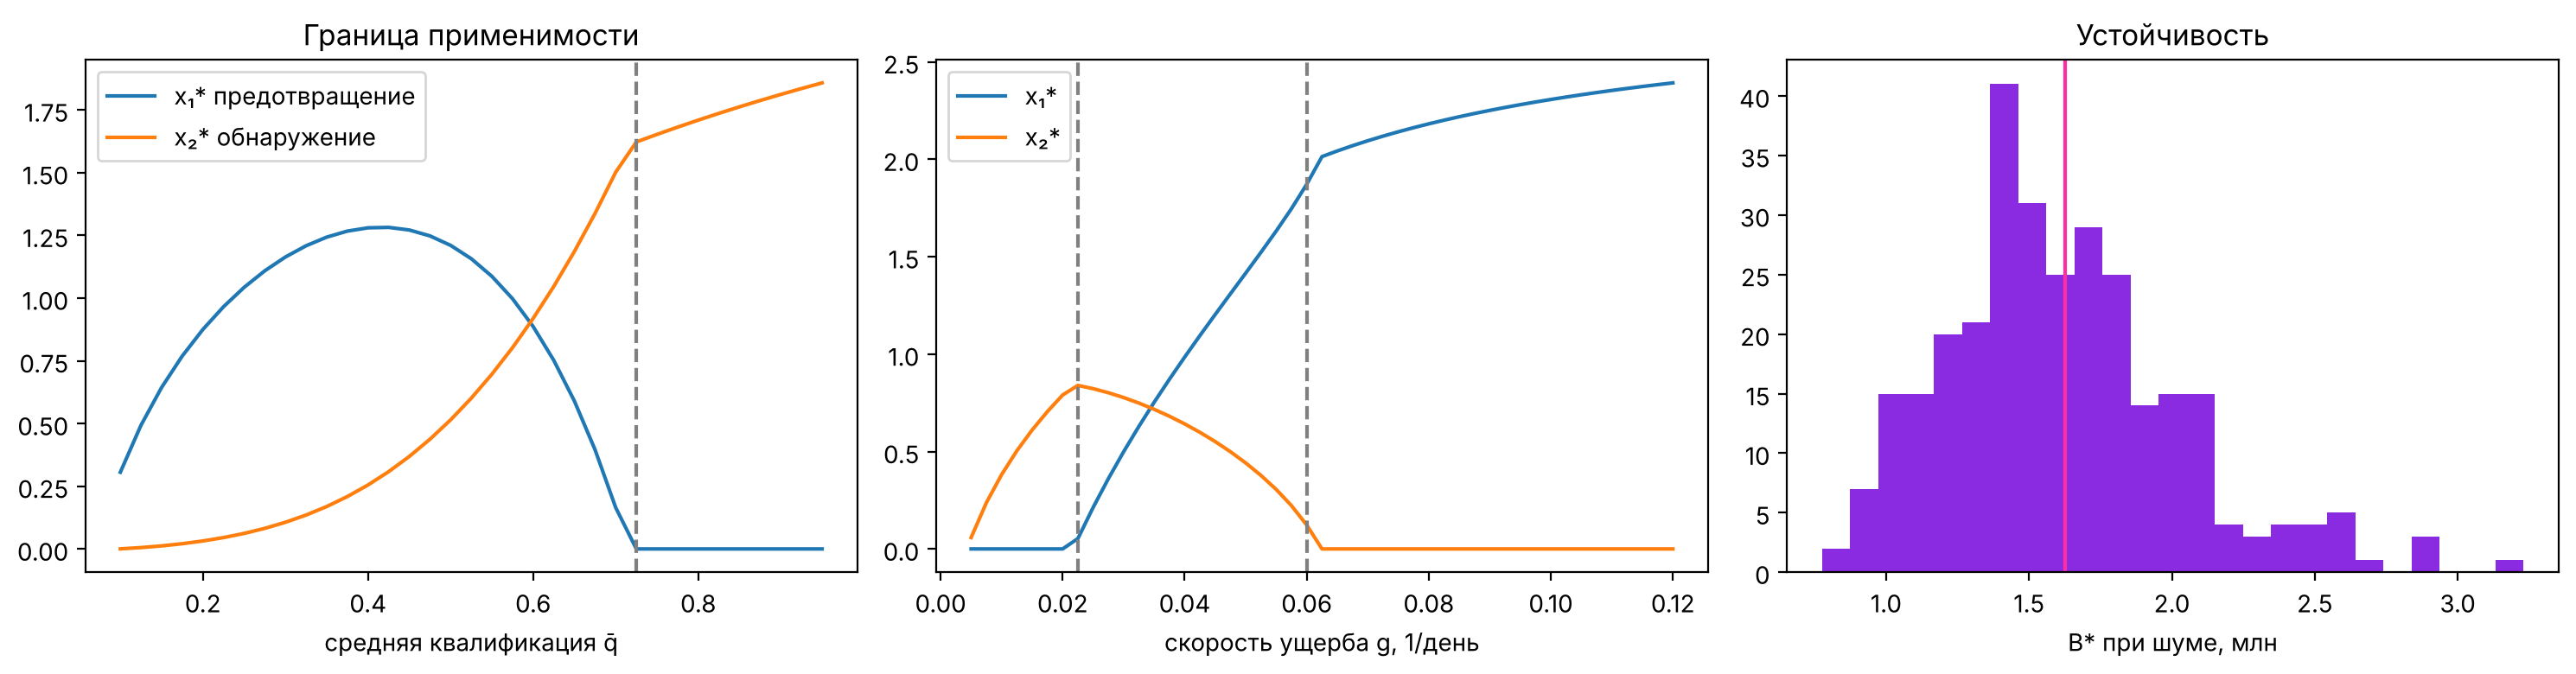

In [13]:
# статические рисунки (для отчёта / слайдов)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(bd.m, bd.x1, label='x₁* предотвращение'); ax[0].plot(bd.m, bd.x2, label='x₂* обнаружение')
ax[0].axvline(m_crit, ls='--', c='gray'); ax[0].set_xlabel('средняя квалификация q̄'); ax[0].legend(); ax[0].set_title('Граница применимости')
ax[1].plot(bg.g, bg.x1, label='x₁*'); ax[1].plot(bg.g, bg.x2, label='x₂*'); [ax[1].axvline(v, ls='--', c='gray') for v in (g_lo, g_hi)]; ax[1].set_xlabel('скорость ущерба g, 1/день'); ax[1].legend()
ax[2].hist(nz.B, bins=25, color='#8A2BE2'); ax[2].axvline(B_opt_direct, c='#FF2DA0'); ax[2].set_xlabel('B* при шуме, млн'); ax[2].set_title('Устойчивость')
plt.tight_layout(); plt.show()

## 6. Границы модели
1. **Модель.** Самое сильное допущение — *одна атака в год и независимость q и t*. Квалифицированный злоумышленник обычно ещё и дольше скрывается (t растёт с q); если это учесть, ценность обнаружения x₂ вырастет, а оптимум сместится в сторону мониторинга.
2. **Данные.** Параметры a, b, g не измеряются напрямую. При шуме 10 % (параметры) и 20 % (стоимость) оптимальный бюджет гуляет в диапазоне 5–95 % (см. таблицу), но «сожаление» от использования номинального решения мало — **плато** функции C широкое: важнее порядок суммы, чем точная цифра.
3. **Интерпретация.** C* — не «гарантированные потери», а среднее по ансамблю атак. Модель не отвечает на вопрос о *катастрофическом* сценарии (хвост распределения) и не учитывает регуляторные штрафы и репутацию.
4. **Практика.** Быстрый ущерб (g > g_hi, шифровальщик) модель «обнуляет» мониторинг — но в реальности обнаружение нужно и для расследования/восстановления, которого в L(q,t) нет. Экспоненциальная отдача $e^{-ax_1}$ предполагает делимость затрат; реальные средства защиты покупаются «пакетами» (лицензия SIEM, штат SOC) — задача становится дискретной. При q̄ ≳ q_crit (APT) модель советует не тратить на предотвращение вовсе, что противоречит практике «базовой гигиены» — это граница применимости, а не рекомендация.